# Credit Risk Modelling — Exploration & Model Selection

This notebook walks through the reasoning behind the pipeline in `src/credit_risk/`:
what the data looks like, which model to choose, where to put the decision threshold,
and how to read an individual prediction.

Run it after `credit-risk generate-data`.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from credit_risk.config import FEATURES, NUMERIC_FEATURES, TARGET
from credit_risk.data import load_dataset
from credit_risk.plotting import ACCENT, ACCENT_LIGHT, MUTED, despine, style

# plotting.py selects the Agg backend so the CLI and CI can render headlessly.
# Switch back to the inline backend now that we want figures in the notebook.
%matplotlib inline

df = load_dataset()
print(f"{len(df):,} applications | default rate {df[TARGET].mean():.2%}")
df.head()

12,000 applications | default rate 17.27%


,application_id,age,annual_income,employment_length,loan_amount,loan_term_months,interest_rate,debt_to_income,credit_score,num_open_accounts,num_past_delinquencies,credit_history_length,revolving_utilization,home_ownership,loan_purpose,employment_status,education,default
0,APP000001,25,75472.29,2.0,19447.96,24,10.51,0.1984,680,8,0,4.1,0.5119,RENT,other,self_employed,bachelors,1
1,APP000002,58,107324.75,3.4,21769.04,12,11.53,0.1975,658,7,2,38.2,0.5310,RENT,other,self_employed,high_school,1
2,APP000003,53,75212.64,3.0,14534.82,48,8.31,0.2979,760,5,0,30.9,0.4134,RENT,debt_consolidation,self_employed,bachelors,0
3,APP000004,42,61658.00,4.0,37088.70,60,9.74,0.3375,740,5,0,19.9,0.3306,OWN,credit_card,part_time,bachelors,0
4,APP000005,42,87059.75,7.0,15036.25,36,11.08,0.4391,698,7,0,20.7,0.5818,MORTGAGE,car,employed,high_school,1


## 1. Class balance

Roughly one in six borrowers defaults. That imbalance is why accuracy is a useless
metric here — predicting "nobody defaults" would score above 80%.

findfont: Failed to find font weight 600, now using 700.


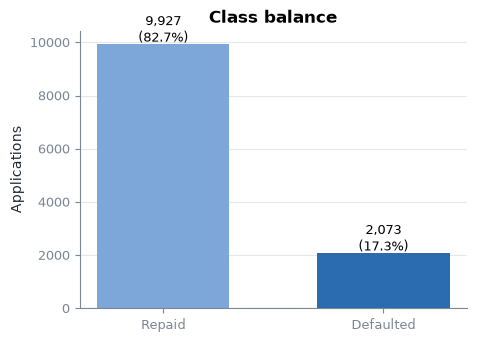

In [2]:
counts = df[TARGET].value_counts().sort_index()
with style():
    fig, ax = plt.subplots(figsize=(5, 3.6))
    ax.bar(["Repaid", "Defaulted"], counts, color=[ACCENT_LIGHT, ACCENT], width=0.6)
    for i, v in enumerate(counts):
        ax.text(i, v + 100, f"{v:,}\n({v/len(df):.1%})", ha="center", fontsize=9)
    ax.set_ylabel("Applications"); ax.set_title("Class balance")
    ax.grid(axis="x", visible=False); despine(ax)
    plt.show()

## 2. Do the risk drivers behave as expected?

Before trusting any model, check that the obvious relationships are present and point
the right way. If they are not, the problem is the data, not the model.

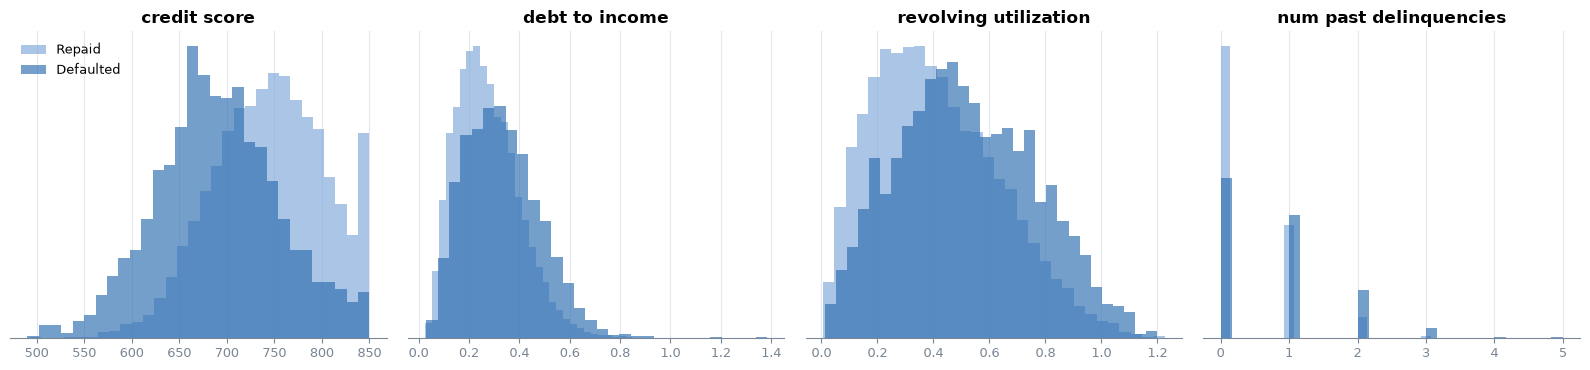

In [3]:
drivers = ["credit_score", "debt_to_income", "revolving_utilization", "num_past_delinquencies"]
with style():
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
    for ax, col in zip(axes, drivers):
        for label, name, colour in [(0, "Repaid", ACCENT_LIGHT), (1, "Defaulted", ACCENT)]:
            ax.hist(df.loc[df[TARGET] == label, col].dropna(), bins=30, alpha=0.65,
                    label=name, color=colour, density=True)
        ax.set_title(col.replace("_", " ")); ax.set_yticks([]); despine(ax, keep=("bottom",))
    axes[0].legend()
    fig.tight_layout(); plt.show()

Defaulters sit lower on credit score and higher on debt-to-income, utilisation and
delinquencies — the structure the model needs to find.

## 3. Correlation with the target

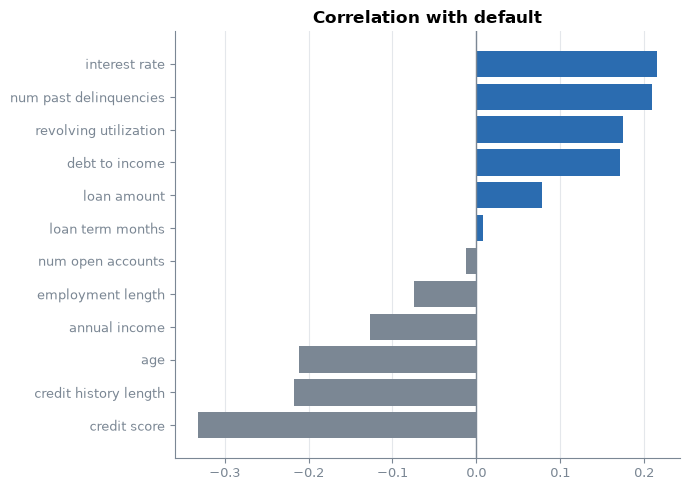

In [4]:
corr = df[NUMERIC_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
with style():
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh(corr.index.str.replace("_", " "), corr.values,
            color=[ACCENT if v > 0 else MUTED for v in corr.values])
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_title("Correlation with default"); ax.grid(axis="y", visible=False); despine(ax)
    fig.tight_layout(); plt.show()

Linear correlations are modest. That is expected and healthy: credit risk is driven by
interactions and thresholds, which is exactly why tree ensembles are worth testing.

## 4. Model selection

Compare three model families by cross-validated ROC-AUC on the training split only.

In [5]:
from credit_risk.train import split_data, compare_models

X_train, X_test, y_train, y_test = split_data(df)
leaderboard = compare_models(X_train, y_train)
leaderboard

  - logistic_regression    CV ROC-AUC 0.7909 (+/- 0.0143)


  - random_forest          CV ROC-AUC 0.7931 (+/- 0.0143)


  - xgboost                CV ROC-AUC 0.7934 (+/- 0.0138)


,model,cv_roc_auc_mean,cv_roc_auc_std
0,xgboost,0.793398,0.013776
1,random_forest,0.793109,0.014285
2,logistic_regression,0.790889,0.014349


The three land within one standard deviation of each other. Reporting the whole
leaderboard rather than the winning number alone is the honest way to present this.

## 5. Calibration and the operating threshold

A ranking model is not enough — a reviewer reading "30% risk" needs that to be true.
Then the cut-off is chosen by expected cost, since approving a defaulter is far more
expensive than declining a good borrower.

In [6]:
from credit_risk.train import calibrate, tune_threshold
from credit_risk.pipeline import build_model
from credit_risk.evaluate import classification_metrics

best = leaderboard.iloc[0]["model"]
model = calibrate(build_model(best), X_train, y_train)
y_prob = model.predict_proba(X_test)[:, 1]

threshold, cost = tune_threshold(y_test, y_prob)
metrics = classification_metrics(y_test, y_prob, threshold)
print(f"model={best}  ROC-AUC={metrics['roc_auc']:.4f}  Brier={metrics['brier_score']:.4f}")
print(f"cost-optimal threshold={threshold:.2f}  recall={metrics['recall']:.3f}")

model=xgboost  ROC-AUC=0.7970  Brier=0.1141
cost-optimal threshold=0.17  recall=0.720


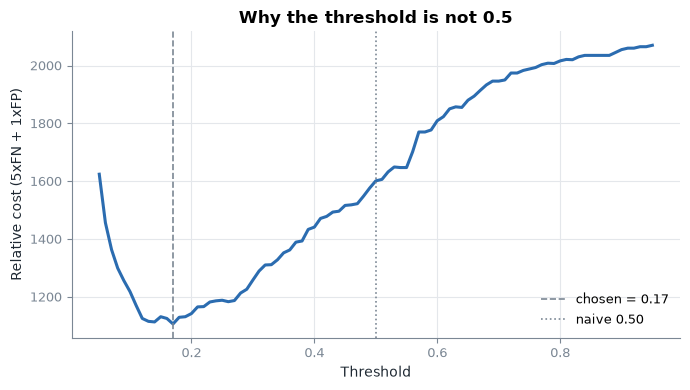

In [7]:
from credit_risk.evaluate import cost_analysis

grid = np.linspace(0.05, 0.95, 91)
costs = [cost_analysis(y_test, y_prob, t)["total_relative_cost"] for t in grid]
with style():
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(grid, costs, lw=2.2, color=ACCENT)
    ax.axvline(threshold, ls="--", color=MUTED, lw=1.2, label=f"chosen = {threshold:.2f}")
    ax.axvline(0.5, ls=":", color=MUTED, lw=1.2, label="naive 0.50")
    ax.set(xlabel="Threshold", ylabel="Relative cost (5xFN + 1xFP)",
           title="Why the threshold is not 0.5")
    ax.legend(); despine(ax); fig.tight_layout(); plt.show()

## 6. Do the decision bands separate real risk?

This is the product question. If the bands do not track actual default rates, the
recommendation is worthless no matter how good the AUC looks.

In [8]:
from credit_risk.evaluate import review_workload

bands = review_workload(y_test, y_prob)
pd.DataFrame(bands).T

,applications,share_of_portfolio,actual_default_rate
RECOMMEND_APPROVE,1701.0,0.7087,0.0841
MANUAL_REVIEW,545.0,0.2271,0.3211
RECOMMEND_DECLINE,154.0,0.0642,0.6299


## 7. Explaining one applicant

Finally, the output a human underwriter actually reads.

In [9]:
from credit_risk.predict import render_adjudication, score_application
from credit_risk.config import DecisionPolicy

pipeline = build_model(best); pipeline.fit(X_train, y_train)
bundle = {"model": model, "uncalibrated_model": pipeline, "model_name": best,
          "threshold": threshold, "policy": DecisionPolicy()}

print(render_adjudication(score_application(bundle, X_test.iloc[[0]], background=X_test)))

  LOAN APPLICATION REVIEW -- (unnamed)

  Estimated default probability : 4.0%
  Risk band                     : Very low
  System recommendation         : RECOMMEND APPROVE

  Why the model scored it this way
  ----------------------------------------------------------------------
  1. v revolving credit utilisation = 0.12          (decreases risk)
  2. v debt-to-income ratio         = 0.09          (decreases risk)
  3. v credit score                 = 757           (decreases risk)
  4. v past delinquencies           = 0             (decreases risk)
  5. ^ age                          = 62            (increases risk)

  Next step: Low estimated risk. Reviewer to confirm and proceed.

  ----------------------------------------------------------------------
  DECISION SUPPORT ONLY -- this is a statistical estimate, not an
  approval or a denial. The final lending determination rests with the
  human reviewer, who should weigh information not captured by the
  model.


## Takeaways

1. Accuracy is the wrong metric on imbalanced credit data — use ROC-AUC, PR-AUC and Brier.
2. The three model families perform comparably; report the leaderboard, not the winner.
3. Calibration matters as much as ranking when a human reads the probability.
4. The threshold is a business decision about cost, not a modelling default.
5. The bands separate real risk — that is what makes the tool useful.

See `MODEL_CARD.md` for limitations and the fairness findings.